# Đánh giá chất lượng dữ liệu Yelp (báo cáo CLDL + TEMPO-DQ)

Notebook mỏng: logic ở package `dq/`, quy tắc ở `config.yaml`, định nghĩa độ đo ở `METRICS.md`. Đơn vị đo là **ô**; mỗi hàm kiểm tra trả True / False / N/A. Chạy từ trên xuống; mọi con số do code sinh ra.

In [1]:
import os, sys
from pathlib import Path
import pandas as pd
from IPython.display import display, Markdown, Image

ROOT = Path.cwd()
if not (ROOT / "dq").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from dq import ASPECTS
from dq.run import load_config, run

DATA_DIR = os.environ.get("DQ_DATA_DIR", r"C:\Users\Yoga\OneDrive\Desktop\UIT code\ds317\archive")
OUT_DIR  = os.environ.get("DQ_OUT_DIR", str(ROOT / "working_v0"))
CONFIG   = os.environ.get("DQ_CONFIG", str(ROOT / "config.yaml"))
LABEL    = os.environ.get("DQ_LABEL", "KQ_v0")      # KQ_v0 = dữ liệu gốc; KQ_v1 = sau cải thiện
pd.set_option("display.float_format", lambda x: f"{x:.6f}")
pd.set_option("display.max_colwidth", 80)

## 1. Chạy đánh giá tự động

In [2]:
cfg = load_config(CONFIG, data_dir=DATA_DIR, out_dir=OUT_DIR, label=LABEL)
result = run(cfg)          # giới hạn bảng: run(cfg, tables=["business", "review"])
frames = result["frames"]

[1/3] Dựng ngữ cảnh tham chiếu liên bảng ...
    business: 150,346 business_id duy nhất
    user: 1,987,897 user_id duy nhất
    review: 6,990,280 dòng làm tham chiếu (số review, trung bình sao)
    hoạt động gần nhất theo POI: 150,346 POI
[2/3] Đánh giá từng bảng ...
    business: 150,346 dòng, 2.9s
    checkin: 13,356,875 dòng, 12.1s
    review: 6,990,280 dòng, 59.3s
    tip: 908,915 dòng, 15.5s
    user: 1,987,897 dòng, 273.1s
[3/3] Xuất báo cáo ...
Xong trong 377.8s. Kết quả ở: C:\Users\Yoga\OneDrive\Desktop\UIT code\ds317\mine\DS317-Project\working_v0


## 2. Ma trận điểm khía cạnh (trung bình điểm các quy tắc xếp hạng; ⚑ = có quy tắc cứng ★ ở mức Tệ)

In [3]:
a = frames["aspects"]
a = a[a["aspect"].isin(ASPECTS)].copy()
a["cell"] = a.apply(lambda r: ("N/A" if r["status"] == "N/A" else "Chỉ báo cáo" if r["status"] == "Chỉ báo cáo"
                               else f"{r['score']:.4f} {r['grade']}" + (" ⚑" if r["flag"] else "")), axis=1)
display(a.pivot(index="table", columns="aspect", values="cell")[ASPECTS])

aspect,Đầy đủ,Duy nhất,Nhất quán,Kịp thời,Hợp lệ,Chính xác
table,,,,,,
business,0.9999 Tốt,0.9995 Tốt,0.9950 Tốt,Chỉ báo cáo,1.0000 Tốt,N/A
checkin,1.0000 Tốt,0.9997 Tốt,1.0000 Tốt,1.0000 Tốt,1.0000 Tốt,N/A
review,1.0000 Tốt,1.0000 Tốt,1.0000 Tốt,1.0000 Tốt,1.0000 Tốt,N/A
tip,1.0000 Tốt,0.9999 Tốt,1.0000 Tốt,1.0000 Tốt,1.0000 Tốt,N/A
user,1.0000 Tốt,1.0000 Tốt,0.8725 Tệ,1.0000 Tốt,0.9971 Tốt,N/A


Khía cạnh **không áp dụng / chỉ báo cáo** và lý do:

In [4]:
display(a[a["status"] != "Đo được"][["table", "aspect", "status", "note"]].reset_index(drop=True))

,table,aspect,status,note
0,business,Kịp thời,Chỉ báo cáo,bảng không có thuộc tính thời gian (chỉ có T4 tham khảo)
1,business,Chính xác,N/A,không có nguồn tham chiếu độc lập tin cậy (báo cáo mục F.1); S7 là đối chiếu...
2,checkin,Chính xác,N/A,không có nguồn tham chiếu độc lập tin cậy (báo cáo mục F.1)
3,review,Chính xác,N/A,không có nguồn tham chiếu độc lập tin cậy (báo cáo mục F.1)
4,tip,Chính xác,N/A,không có nguồn tham chiếu độc lập tin cậy (báo cáo mục F.1)
5,user,Chính xác,N/A,không có nguồn tham chiếu độc lập tin cậy (báo cáo mục F.1); S8 là đối chiếu...


## 3. Chi tiết từng quy tắc: số ô xét, số ô vi phạm, điểm, xếp hạng, hành động

In [5]:
r = frames["rules"]
cols = ["table", "rule_id", "aspect", "level", "n_units", "n_violations", "score", "grade", "action"]
display(r[cols].sort_values(["table", "aspect", "rule_id"]).reset_index(drop=True))

,table,rule_id,aspect,level,n_units,n_violations,score,grade,action
0,business,U1,Duy nhất,star,150346,0,1.000000,Tốt,Dùng trực tiếp
1,business,U3,Duy nhất,general,145202,136,0.999063,Tốt,Dùng trực tiếp
2,business,V0,Hợp lệ,general,751730,0,1.000000,Tốt,Dùng trực tiếp
3,business,V1,Hợp lệ,star,150346,0,1.000000,Tốt,Dùng trực tiếp
4,business,V10,Hợp lệ,general,127123,0,1.000000,Tốt,Dùng trực tiếp
...,...,...,...,...,...,...,...,...,...
56,user,S3,Nhất quán,general,1987897,17665,0.991114,Tốt,Dùng trực tiếp
57,user,S4,Nhất quán,general,90979,0,1.000000,Tốt,Dùng trực tiếp
58,user,S8,Nhất quán,general,1987897,742635,0.626422,Tệ,Phải sửa / điền / loại trước khi dùng
59,user,C6,Đầy đủ,star,7951588,0,1.000000,Tốt,Dùng trực tiếp


## 4. Mức bộ dữ liệu (trung bình các bảng)

In [6]:
display(frames["dataset"])

,aspect,n_tables,tables,score,grade,flag,flagged_tables
0,Đầy đủ,5,"business,checkin,review,tip,user",0.999971,Tốt,False,
1,Duy nhất,5,"business,checkin,review,tip,user",0.999838,Tốt,False,
2,Nhất quán,5,"business,checkin,review,tip,user",0.973495,Chú ý,False,
3,Kịp thời,4,"checkin,review,tip,user",1.000000,Tốt,False,
4,Hợp lệ,5,"business,checkin,review,tip,user",0.999426,Tốt,False,


## 5. Quy tắc vi phạm nhiều nhất và giá trị lỗi phổ biến

In [7]:
display(r[r["n_violations"] > 0].sort_values("n_violations", ascending=False).head(15)[["table", "rule_id", "n_violations", "score", "grade", "top_values"]])

,table,rule_id,n_violations,score,grade,top_values
48,user,C7,2775250,0.301963,Chỉ báo cáo,elite: ''×200000 | friends: '[]'×200000
59,user,S8,742635,0.626422,Tệ,average_stars: '3.0'×13481; '4.0'×10970; '3.67'×8970; '2.33'×4544; '3.5'×4093
17,business,S6,67362,0.551953,Chỉ báo cáo,review_count: '5'×2020; '6'×1757; '7'×1711; '8'×1607; '9'×1599
2,business,C7,42094,0.906673,Chỉ báo cáo,address: ''×5127 | hours: nan×23223 | attributes: nan×13744
54,user,V9,39929,0.979914,Chú ý,"elite: '2019,20,20,2021'×8058; '2018,2019,20,20,2021'×6701; '20,20,2021'×506..."
57,user,S3,17665,0.991114,Tốt,review_count: '1'×5200; '2'×2924; '3'×1750; '4'×1403; '5'×914
19,business,T4,14045,0.882663,Chỉ báo cáo,is_open: '1'×14045
24,checkin,U1,3543,0.999735,Chú ý,
15,business,S5a,1791,0.988087,Chú ý,city: 'St Petersburg'×387; 'St Louis'×357; 'King Of Prussia'×134; 'St. Charl...
18,business,S7,440,0.997073,Tốt,stars: '4.0'×105; '4.5'×82; '3.5'×57; '3.0'×43; '5.0'×42


Chỉ số chỉ báo cáo (C8 độ phủ, S6 tổng review_count so với số review quan sát, T4 tỷ lệ POI còn hoạt động):

In [8]:
display(frames["metrics"])

,table,rule_id,metric,value,numerator,denominator,note
0,business,S6,tổng giá trị / tổng tham chiếu,0.964984,6745508.000000,6990280.000000,Σ review_count (mỗi business_id một lần) so với Σ review_n_by_business; chên...
1,checkin,C8,độ phủ,0.877509,131930.000000,150346.000000,business_id khác nhau nằm trong business.business_id


## 6. Biểu đồ theo bảng

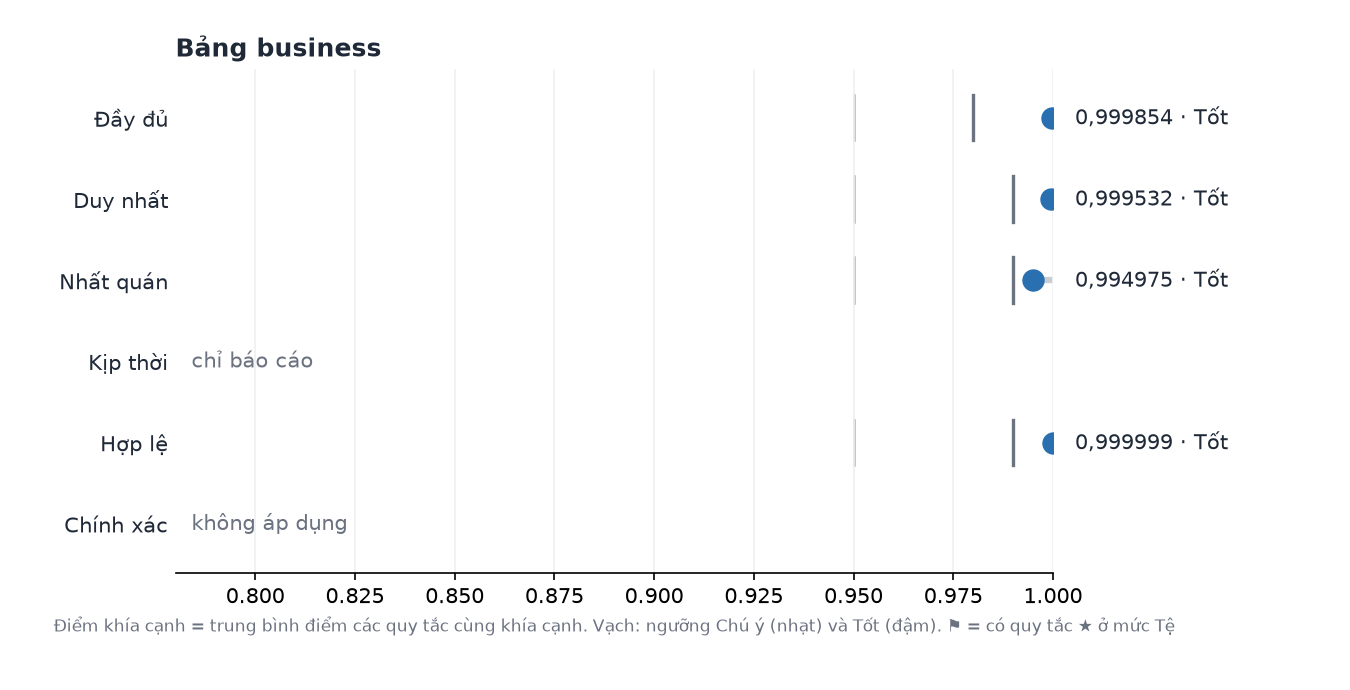

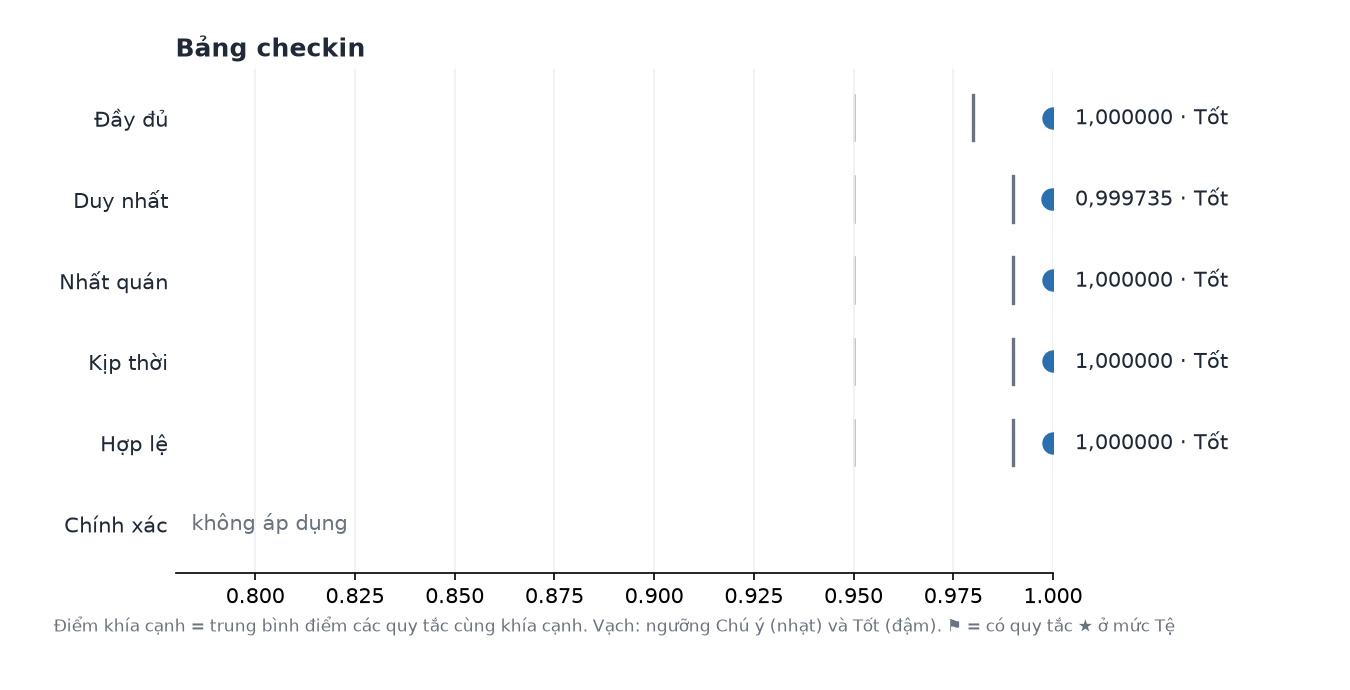

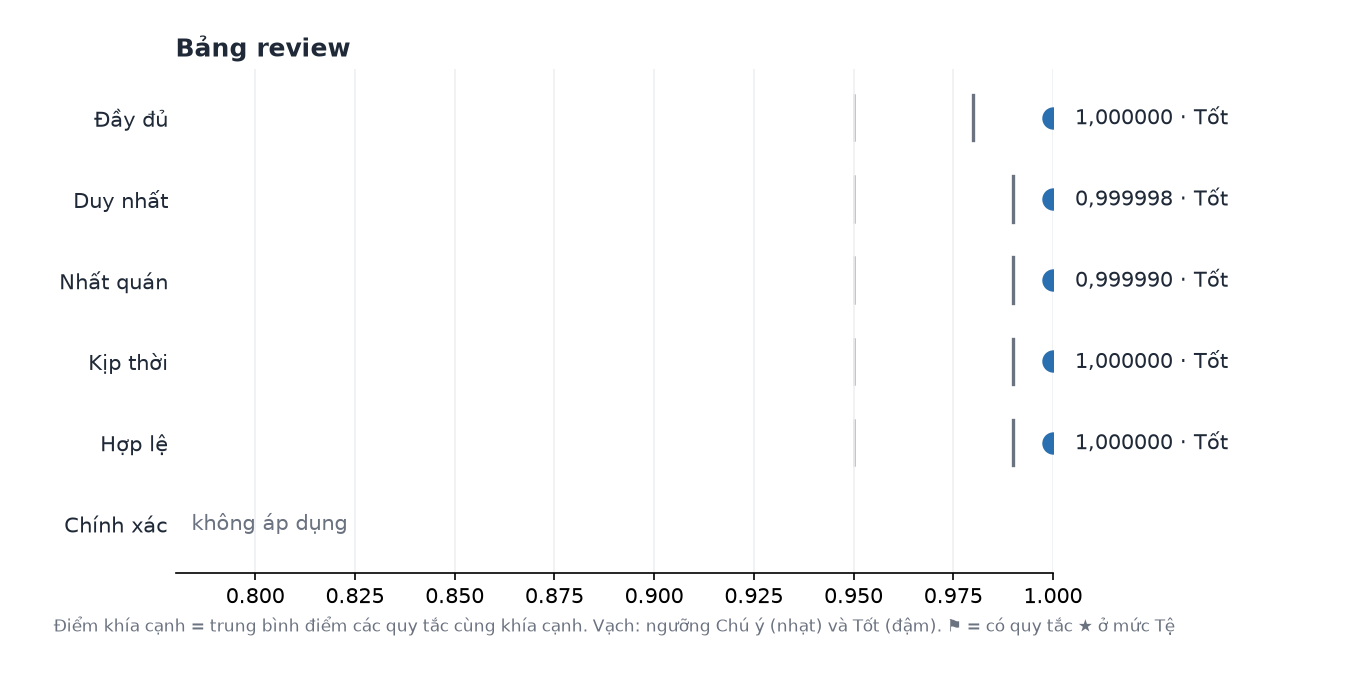

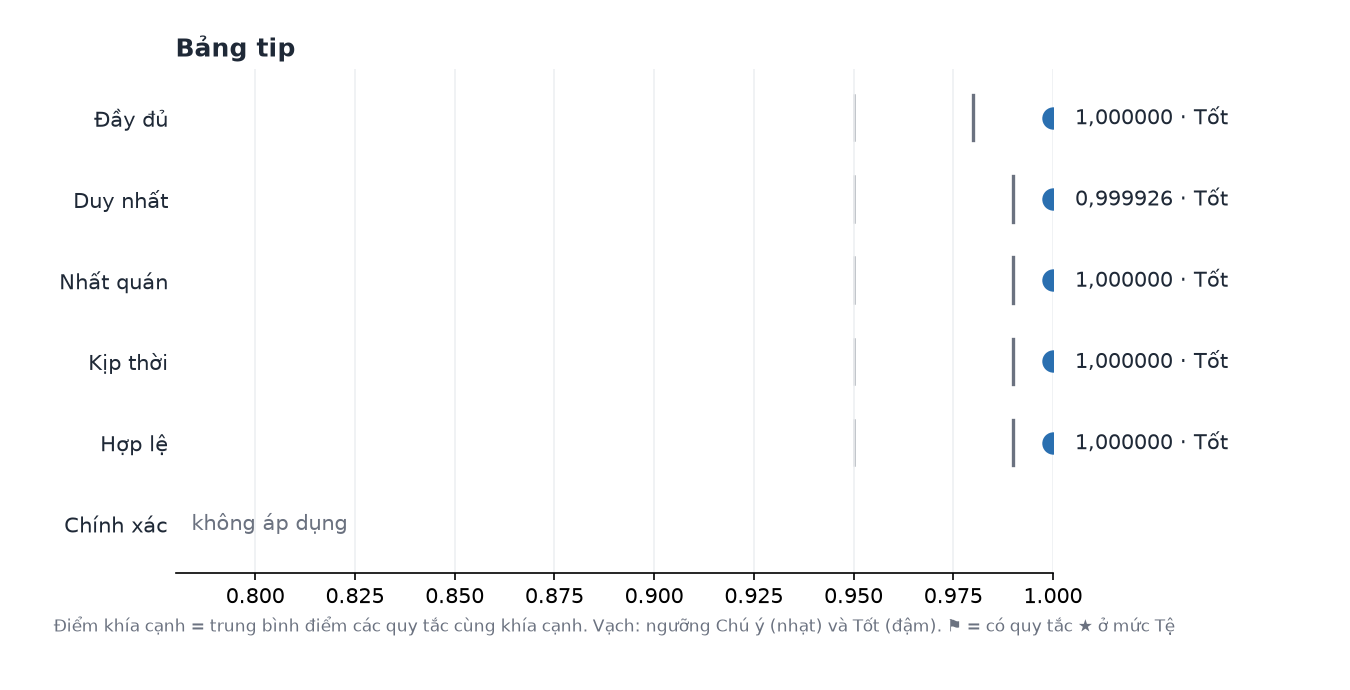

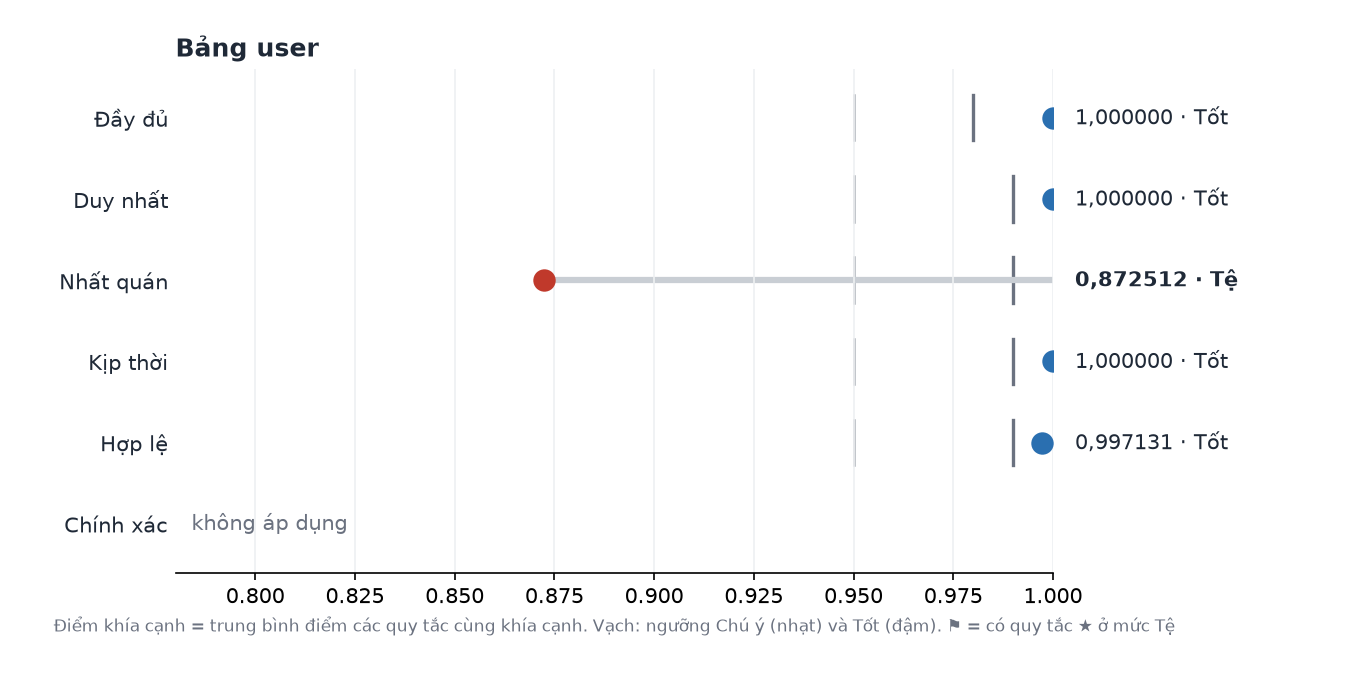

In [9]:
for t in cfg["tables"]:
    p = Path(OUT_DIR) / f"chart_{t}.png"
    if p.exists():
        display(Image(filename=str(p)))

## 7. Dẫn chứng: ô lỗi mẫu (đủ khóa để tra lại dữ liệu gốc)

In [10]:
smp = frames["samples"]
RULE = None   # ví dụ "U1"; None = 3 mẫu đầu của mọi quy tắc
view = smp[smp["rule_id"] == RULE] if RULE else smp.groupby(["table", "rule_id"]).head(3)
display(view.head(60))

,table,rule_id,aspect,row_position,record,cell,value,reference_name,reference_value
0,business,C2,Đầy đủ,853,business_id='6cPVGUOVlHa6TwlgU08IXQ'; name='Dr.Green',postal_code,'',NaN,NaN
1,business,C2,Đầy đủ,2617,"business_id='siwG4ZM7RjUDO52DI84m3w'; name=""Ray's Vegan Soul""",postal_code,'',NaN,NaN
2,business,C2,Đầy đủ,2984,business_id='m84BCUA6aDi03mRyufHYBw'; name='Harlow Pest & Sanitation Control',postal_code,'',NaN,NaN
40,business,C7,Đầy đủ,11,business_id='eEOYSgkmpB90uNA7lDOMRA'; name='Vietnamese Food Truck',address,'',NaN,NaN
41,business,C7,Đầy đủ,39,business_id='fSCNwMtNNQY9QT69Cj9fiA'; name='Sierra Pro Events',address,'',NaN,NaN
42,business,C7,Đầy đủ,51,business_id='REwfwz-_-CMQ7Np5UVi9Qg'; name='Jennie Deckert',address,'',NaN,NaN
100,business,V2,Hợp lệ,144012,business_id='g0fYqQRRKmYIfChE4jMLsg'; name='All Service Citgo',longitude,-73.2004570502,NaN,NaN
101,business,V8,Hợp lệ,98685,business_id='IvQs2hhXKZ4NgZhVZ5jjjQ'; name='Pumpernickles Catering',state,'XMS',NaN,NaN
102,business,U3,Duy nhất,11786,business_id='hMcgO98QaOFmQVTfCUeGzw'; name='Dentistry For Life',"(name, address, postal_code)","""name='Dentistry For Life'; address='1601 Walnut St, Ste 1...; postal_code='...",NaN,NaN
103,business,U3,Duy nhất,13318,business_id='m1XtvXqnqKgZvgKB8uYKIw'; name='Preferred Party Place',"(name, address, postal_code)","""name='Preferred Party Place'; address='1651 Sicklerville Rd'; postal_code='...",NaN,NaN


## 8. Hồ sơ thời gian (thông tin) và đối chiếu TEMPO-DQ Eq.(2)

In [11]:
display(frames["profile"].drop(columns=["by_year"]))
display(frames["eq2"][frames["eq2"]["n_missing"] > 0])

,table,column,n,min,max,n_after_T_ref,n_before_T_start
0,checkin,checkin_time,13356875,2009-12-30 02:53:27,2022-01-19 16:48:37,0,0
1,review,date,6990280,2005-02-16 03:23:22,2022-01-19 19:48:45,0,0
2,tip,date,908915,2009-04-16 13:11:49,2022-01-19 20:38:55,0,0
3,user,yelping_since,1987897,2004-10-12 08:46:11,2022-01-19 17:15:47,0,0


,table,column,n_missing,ratio_missing,covered_by_rules
2,business,address,5127,0.034101,C7
5,business,postal_code,73,0.000486,C2
11,business,attributes,13744,0.091416,C7
12,business,categories,103,0.000685,C2
13,business,categories_list,103,0.000685,—
14,business,hours,23223,0.154464,C7


## 9. So sánh trước - sau (sau khi có KQ_v1)

`python -m dq.compare working_v0 working_v1 --out so_sanh.md`

## 10. Báo cáo tự sinh (`report.md`)

In [12]:
display(Markdown(result["report_md"]))

# Báo cáo chất lượng dữ liệu Yelp — KQ_v0

- Chạy lúc 2026-10-28T22:01:03 · mốc snapshot T_ref = 2022-01-19 · khung Kịp thời [2005-02-16; 2022-01-19] · code 2.0.0
- Cấu hình `c:\Users\Yoga\OneDrive\Desktop\UIT code\ds317\mine\DS317-Project\config.yaml` (sha256 1f83eee8c825)
- **Cách tính** (báo cáo CLDL, A.1): điểm quy tắc = 1 − (số ô lỗi / tổng số ô được xét); điểm khía cạnh = trung bình các quy tắc cùng khía cạnh (bỏ quy tắc *chỉ báo cáo*); khía cạnh bị gắn cờ ⚑ nếu có quy tắc ★ ở mức Tệ dù điểm trung bình cao.
- **Xếp hạng** (Bảng A.1): Đầy đủ: Tốt ≥ 0,98, Tệ < 0,95; Hợp lệ: Tốt ≥ 0,99, Tệ < 0,95; Duy nhất: Tốt ≥ 0,99, Tệ < 0,95; Nhất quán: Tốt ≥ 0,99, Tệ < 0,95; Chính xác: Tốt ≥ 0,90, Tệ < 0,80; Kịp thời: Tốt ≥ 0,99, Tệ < 0,95; quy tắc ★: Tốt ≥ 0,999, Tệ < 0,99.

## 1. Điểm khía cạnh theo bảng

| Bảng (số dòng) | Đầy đủ | Duy nhất | Nhất quán | Kịp thời | Hợp lệ | Chính xác |
|---|---:|---:|---:|---:|---:|---:|
| business (150,346) | 0,999854 · Tốt | 0,999532 · Tốt | 0,994975 · Tốt | chỉ báo cáo | 0,999999 · Tốt | N/A |
| checkin (13,356,875) | 1,000000 · Tốt | 0,999735 · Tốt | 1,000000 · Tốt | 1,000000 · Tốt | 1,000000 · Tốt | N/A |
| review (6,990,280) | 1,000000 · Tốt | 0,999998 · Tốt | 0,999990 · Tốt | 1,000000 · Tốt | 1,000000 · Tốt | N/A |
| tip (908,915) | 1,000000 · Tốt | 0,999926 · Tốt | 1,000000 · Tốt | 1,000000 · Tốt | 1,000000 · Tốt | N/A |
| user (1,987,897) | 1,000000 · Tốt | 1,000000 · Tốt | 0,872512 · Tệ | 1,000000 · Tốt | 0,997131 · Tốt | N/A |

Mức bộ dữ liệu (trung bình cộng điểm các bảng đo được): Đầy đủ 0,999971 · Tốt; Duy nhất 0,999838 · Tốt; Nhất quán 0,973495 · Chú ý; Kịp thời 1,000000 · Tốt; Hợp lệ 0,999426 · Tốt.

## 2. Chi tiết từng quy tắc

Đơn vị = ô (khóa ghép U2–U4 tính một ô tổ hợp). `Vi phạm` = số ô False. ★ = quy tắc cứng.

### business

| Mã | Khía cạnh | Phạm vi | Quy tắc | Ô xét | Vi phạm | Điểm | Xếp hạng | Xử lý |
|---|---|---|---|---:|---:|---:|---|---|
| ★ C1 | Đầy đủ | nội bảng | business_id, name, latitude, longitude, stars, review_count, is_open ≠ null | 1,052,422 | 0 | 1,000000 | Tốt | Dùng trực tiếp |
| C2 | Đầy đủ | nội bảng | city, state, postal_code, categories ≠ null | 601,384 | 176 | 0,999707 | Tốt | Dùng trực tiếp |
| C7 | Đầy đủ | nội bảng | tỷ lệ thiếu của address, hours, attributes (chỉ báo cáo) | 451,038 | 42,094 | 0,906673 | Chỉ báo cáo | Chỉ báo cáo |
| V0 | Hợp lệ | nội bảng | (bổ sung) ô số phải ép được số, nếu không V2-V5 sẽ bỏ qua ô đó | 751,730 | 0 | 1,000000 | Tốt | Dùng trực tiếp |
| ★ V1 | Hợp lệ | nội bảng | business_id khớp chuỗi 22 ký tự [A-Za-z0-9_-] | 150,346 | 0 | 1,000000 | Tốt | Dùng trực tiếp |
| ★ V2 | Hợp lệ | nội bảng | latitude ∈ [27; 54], longitude ∈ [-121; -74] | 300,692 | 1 | 0,999997 | Tốt | Xử lý mọi vi phạm (quy tắc ★) |
| ★ V3 | Hợp lệ | nội bảng | stars ∈ {1; 1,5; …; 5} | 150,346 | 0 | 1,000000 | Tốt | Dùng trực tiếp |
| ★ V4 | Hợp lệ | nội bảng | review_count là số nguyên ≥ 0 | 150,346 | 0 | 1,000000 | Tốt | Dùng trực tiếp |
| ★ V5 | Hợp lệ | nội bảng | is_open ∈ {0, 1} | 150,346 | 0 | 1,000000 | Tốt | Dùng trực tiếp |
| V8 | Hợp lệ | nội bảng | state là chuỗi 2 ký tự [A-Z] (ngoại lệ được ghi nhận riêng ở cột top_values) | 150,346 | 1 | 0,999993 | Tốt | Dùng trực tiếp |
| V10 | Hợp lệ | nội bảng | hours có dạng H:M-H:M; khung 0:0-0:0 chỉ gắn nhãn 'cần kiểm chứng' (n_flagged), không tính lỗi (⚠ 31674 ô cần kiểm chứng) | 127,123 | 0 | 1,000000 | Tốt | Dùng trực tiếp |
| V12a | Hợp lệ | nội bảng | postal_code giữ kiểu chuỗi | 150,346 | 0 | 1,000000 | Tốt | Dùng trực tiếp |
| V12b | Hợp lệ | nội bảng | attributes parse được thành object | 136,602 | 0 | 1,000000 | Tốt | Dùng trực tiếp |
| ★ U1 | Duy nhất | nội bảng | business_id không trùng (Tốt = 1) | 150,346 | 0 | 1,000000 | Tốt | Dùng trực tiếp |
| U3 | Duy nhất | nội bảng | bộ (name, address, postal_code) không lặp; name trùng riêng lẻ không tính lỗi | 145,202 | 136 | 0,999063 | Tốt | Dùng trực tiếp |
| S5a | Nhất quán | nội bảng | city chỉ có một cách viết chuẩn sau chuẩn hóa (trim, lower, bỏ dấu) | 150,346 | 1,791 | 0,988087 | Chú ý | Ghi nhận, gắn cờ hoặc xử lý nhẹ |
| S5b | Nhất quán | nội bảng | city thuộc đúng state (cặp city–state không hiếm; city >= 20 dòng, cặp chiếm >= 1%) | 147,615 | 35 | 0,999763 | Tốt | Dùng trực tiếp |
| S6 | Nhất quán | liên bảng | review_count so với số review trong file (chỉ báo cáo, chưa xếp hạng; kèm tổng và tỷ lệ) | 150,346 | 67,362 | 0,551953 | Chỉ báo cáo | Chỉ báo cáo |
| S7 | Nhất quán | liên bảng | stars lệch ≤ 0,5 so với trung bình review.stars của POI trong file review | 150,346 | 440 | 0,997073 | Tốt | Dùng trực tiếp |
| T4 | Kịp thời | liên bảng | tỷ lệ POI is_open = 1 có ít nhất một review/tip/check-in trong 24 tháng trước T_ref (chỉ báo cáo) | 119,698 | 14,045 | 0,882663 | Chỉ báo cáo | Chỉ báo cáo |

### checkin

| Mã | Khía cạnh | Phạm vi | Quy tắc | Ô xét | Vi phạm | Điểm | Xếp hạng | Xử lý |
|---|---|---|---|---:|---:|---:|---|---|
| ★ C5 | Đầy đủ | nội bảng | business_id ≠ null, mốc check-in không rỗng | 26,713,750 | 0 | 1,000000 | Tốt | Dùng trực tiếp |
| C8 | Đầy đủ | liên bảng | độ phủ checkin/business (chỉ báo cáo) | 0 | 0 | — | Chỉ báo cáo | Chỉ báo cáo |
| ★ V1 | Hợp lệ | nội bảng | business_id khớp chuỗi 22 ký tự | 13,356,875 | 0 | 1,000000 | Tốt | Dùng trực tiếp |
| ★ V6 | Hợp lệ | nội bảng | mốc check-in đúng định dạng YYYY-MM-DD HH:MM:SS | 13,356,875 | 0 | 1,000000 | Tốt | Dùng trực tiếp |
| ★ U1 | Duy nhất | nội bảng | cặp (business_id, checkin_time) không trùng (Tốt = 1) | 13,356,875 | 3,543 | 0,999735 | Chú ý | Xử lý mọi vi phạm (quy tắc ★) |
| ★ S1 | Nhất quán | liên bảng | business_id ∈ business | 13,356,875 | 0 | 1,000000 | Tốt | Dùng trực tiếp |
| ★ T3 | Kịp thời | nội bảng | mọi mốc check-in ≤ T_ref | 13,356,875 | 0 | 1,000000 | Tốt | Dùng trực tiếp |

### review

| Mã | Khía cạnh | Phạm vi | Quy tắc | Ô xét | Vi phạm | Điểm | Xếp hạng | Xử lý |
|---|---|---|---|---:|---:|---:|---|---|
| ★ C3 | Đầy đủ | nội bảng | cả 9 trường ≠ null, text dài ≥ 1 | 62,912,520 | 0 | 1,000000 | Tốt | Dùng trực tiếp |
| V0 | Hợp lệ | nội bảng | (bổ sung) ô số phải ép được số | 27,961,120 | 0 | 1,000000 | Tốt | Dùng trực tiếp |
| ★ V1 | Hợp lệ | nội bảng | review_id, user_id, business_id khớp chuỗi 22 ký tự | 20,970,840 | 0 | 1,000000 | Tốt | Dùng trực tiếp |
| ★ V3 | Hợp lệ | nội bảng | review.stars ∈ {1…5} (số nguyên) | 6,990,280 | 0 | 1,000000 | Tốt | Dùng trực tiếp |
| ★ V4 | Hợp lệ | nội bảng | useful, funny, cool là số nguyên ≥ 0 | 20,970,840 | 7 | 1,000000 | Tốt | Xử lý mọi vi phạm (quy tắc ★) |
| ★ V6 | Hợp lệ | nội bảng | date đúng định dạng YYYY-MM-DD HH:MM:SS | 6,990,280 | 0 | 1,000000 | Tốt | Dùng trực tiếp |
| ★ U1 | Duy nhất | nội bảng | review_id không trùng (Tốt = 1) | 6,990,280 | 0 | 1,000000 | Tốt | Dùng trực tiếp |
| U4 | Duy nhất | nội bảng | bộ (user_id, business_id, date) không lặp | 6,990,280 | 25 | 0,999996 | Tốt | Dùng trực tiếp |
| ★ S1 | Nhất quán | liên bảng | business_id ∈ business; user_id ∈ user | 13,980,560 | 33 | 0,999998 | Tốt | Xử lý mọi vi phạm (quy tắc ★) |
| S2 | Nhất quán | liên bảng | review.date ≥ user.yelping_since của chính người viết | 6,990,247 | 117 | 0,999983 | Tốt | Dùng trực tiếp |
| ★ T1 | Kịp thời | nội bảng | review.date ∈ [T_start; T_ref] | 6,990,280 | 0 | 1,000000 | Tốt | Dùng trực tiếp |

### tip

| Mã | Khía cạnh | Phạm vi | Quy tắc | Ô xét | Vi phạm | Điểm | Xếp hạng | Xử lý |
|---|---|---|---|---:|---:|---:|---|---|
| ★ C4 | Đầy đủ | nội bảng | user_id, business_id, text, date ≠ null | 3,635,660 | 0 | 1,000000 | Tốt | Dùng trực tiếp |
| V0 | Hợp lệ | nội bảng | (bổ sung) ô số phải ép được số | 908,915 | 0 | 1,000000 | Tốt | Dùng trực tiếp |
| ★ V1 | Hợp lệ | nội bảng | user_id, business_id khớp chuỗi 22 ký tự | 1,817,830 | 0 | 1,000000 | Tốt | Dùng trực tiếp |
| ★ V4 | Hợp lệ | nội bảng | compliment_count là số nguyên ≥ 0 | 908,915 | 0 | 1,000000 | Tốt | Dùng trực tiếp |
| ★ V6 | Hợp lệ | nội bảng | date đúng định dạng YYYY-MM-DD HH:MM:SS | 908,915 | 0 | 1,000000 | Tốt | Dùng trực tiếp |
| U2 | Duy nhất | nội bảng | tip không có khóa riêng nên bộ (user_id, business_id, date, text) không lặp | 908,915 | 67 | 0,999926 | Tốt | Dùng trực tiếp |
| ★ S1 | Nhất quán | liên bảng | business_id ∈ business; user_id ∈ user | 1,817,830 | 0 | 1,000000 | Tốt | Dùng trực tiếp |
| S2 | Nhất quán | liên bảng | tip.date ≥ user.yelping_since của chính người viết | 908,915 | 0 | 1,000000 | Tốt | Dùng trực tiếp |
| ★ T1 | Kịp thời | nội bảng | tip.date ∈ [T_start; T_ref] | 908,915 | 0 | 1,000000 | Tốt | Dùng trực tiếp |

### user

| Mã | Khía cạnh | Phạm vi | Quy tắc | Ô xét | Vi phạm | Điểm | Xếp hạng | Xử lý |
|---|---|---|---|---:|---:|---:|---|---|
| ★ C6 | Đầy đủ | nội bảng | user_id, yelping_since, review_count, average_stars ≠ null | 7,951,588 | 0 | 1,000000 | Tốt | Dùng trực tiếp |
| C7 | Đầy đủ | nội bảng | tỷ lệ 'không có' của elite ('' ) và friends ('None' hoặc '[]') sau chuẩn hóa (chỉ báo cáo) | 3,975,794 | 2,775,250 | 0,301963 | Chỉ báo cáo | Chỉ báo cáo |
| V0 | Hợp lệ | nội bảng | (bổ sung) ô số phải ép được số | 33,794,249 | 0 | 1,000000 | Tốt | Dùng trực tiếp |
| ★ V1 | Hợp lệ | nội bảng | user_id khớp chuỗi 22 ký tự | 1,987,897 | 0 | 1,000000 | Tốt | Dùng trực tiếp |
| ★ V4 | Hợp lệ | nội bảng | review_count, useful, funny, cool, fans, compliment_* là số nguyên ≥ 0 | 31,806,352 | 0 | 1,000000 | Tốt | Dùng trực tiếp |
| ★ V6 | Hợp lệ | nội bảng | yelping_since đúng định dạng YYYY-MM-DD HH:MM:SS | 1,987,897 | 0 | 1,000000 | Tốt | Dùng trực tiếp |
| ★ V7 | Hợp lệ | nội bảng | average_stars ∈ [1; 5] | 1,987,897 | 0 | 1,000000 | Tốt | Dùng trực tiếp |
| V9 | Hợp lệ | nội bảng | elite là '' hoặc danh sách năm 4 chữ số (bắt lỗi dạng '20,20') | 1,987,897 | 39,929 | 0,979914 | Chú ý | Ghi nhận, gắn cờ hoặc xử lý nhẹ |
| V11 | Hợp lệ | nội bảng | friends là danh sách rỗng ('None', '[]') hoặc mọi phần tử là user_id đúng định dạng 22 ký tự (thêm max_rows để lấy mẫu nếu RAM hạn chế) | 1,987,897 | 0 | 1,000000 | Tốt | Dùng trực tiếp |
| ★ U1 | Duy nhất | nội bảng | user_id không trùng (Tốt = 1) | 1,987,897 | 0 | 1,000000 | Tốt | Dùng trực tiếp |
| S3 | Nhất quán | liên bảng | user.review_count ≥ số review của user đó có trong file review (file là tập con) | 1,987,897 | 17,665 | 0,991114 | Tốt | Dùng trực tiếp |
| S4 | Nhất quán | nội bảng | elite: mỗi năm ≥ năm của yelping_since và ≤ 2022 | 90,979 | 0 | 1,000000 | Tốt | Dùng trực tiếp |
| S8 | Nhất quán | liên bảng | average_stars lệch ≤ 0,5 so với trung bình review.stars của user trong file review | 1,987,897 | 742,635 | 0,626422 | Tệ | Phải sửa / điền / loại trước khi dùng |
| ★ T2 | Kịp thời | nội bảng | user.yelping_since ∈ [2004-07-01; T_ref] (cận dưới là thời điểm Yelp thành lập 07/2004, sớm hơn T_start của review; cần nhóm xác nhận) | 1,987,897 | 0 | 1,000000 | Tốt | Dùng trực tiếp |

## 3. Quy tắc cần xử lý

| Bảng | Mã | Khía cạnh | Vi phạm | Điểm | Xếp hạng | Giá trị vi phạm phổ biến |
|---|---|---|---:|---:|---|---|
| user | S8 | Nhất quán | 742,635 | 0,626422 | Tệ | average_stars: '3.0'×13481; '4.0'×10970; '3.67'×8970; '2.33'×4544; '3.5'×4093 |
| checkin | ★ U1 | Duy nhất | 3,543 | 0,999735 | Chú ý | — |
| review | ★ S1 | Nhất quán | 33 | 0,999998 | Tốt | user_id: 'lzpM_Vf2rKA4ivGtAIOH4w'×2; 'tquAg8GqbhN5k6Hkd23M0A'×1; '5iBVQ3OeK8lV4Z_4PXc1Xw'×1; 'u8cq-5zzD7dPSa3LR8rIMw'×1; '433BzxUeQAmRmK0g06UAfA'×1 |
| review | ★ V4 | Hợp lệ | 7 | 1,000000 | Tốt | useful: '-1'×4 | funny: '-1'×2 | cool: '-1'×1 |
| business | ★ V2 | Hợp lệ | 1 | 0,999997 | Tốt | longitude: '-73.2004570502'×1 |

## 4. Chỉ báo cáo (không xếp hạng)

- **business · C7** — tỷ lệ thiếu của address, hours, attributes (chỉ báo cáo): 42,094/451,038 ô → tỷ lệ đạt 0,9067.
- **business · S6** — review_count so với số review trong file (chỉ báo cáo, chưa xếp hạng; kèm tổng và tỷ lệ): 67,362/150,346 ô → tỷ lệ đạt 0,5520.
- **business · T4** — tỷ lệ POI is_open = 1 có ít nhất một review/tip/check-in trong 24 tháng trước T_ref (chỉ báo cáo): 14,045/119,698 ô → tỷ lệ đạt 0,8827.
- **user · C7** — tỷ lệ 'không có' của elite ('' ) và friends ('None' hoặc '[]') sau chuẩn hóa (chỉ báo cáo): 2,775,250/3,975,794 ô → tỷ lệ đạt 0,3020.
- **business · S6** — tổng giá trị / tổng tham chiếu: 0,9650 (6,745,508/6,990,280); Σ review_count (mỗi business_id một lần) so với Σ review_n_by_business; chênh 244,772.
- **checkin · C8** — độ phủ: 0,8775 (131,930/150,346); business_id khác nhau nằm trong business.business_id.

## 5. Khía cạnh không áp dụng và cảnh báo cấu hình

- **business · Kịp thời**: bảng không có thuộc tính thời gian (chỉ có T4 tham khảo)
- **business · Chính xác**: không có nguồn tham chiếu độc lập tin cậy (báo cáo mục F.1); S7 là đối chiếu chéo, xếp ở Nhất quán
- **checkin · Chính xác**: không có nguồn tham chiếu độc lập tin cậy (báo cáo mục F.1)
- **review · Chính xác**: không có nguồn tham chiếu độc lập tin cậy (báo cáo mục F.1)
- **tip · Chính xác**: không có nguồn tham chiếu độc lập tin cậy (báo cáo mục F.1)
- **user · Chính xác**: không có nguồn tham chiếu độc lập tin cậy (báo cáo mục F.1); S8 là đối chiếu chéo, xếp ở Nhất quán
- ℹ **business**: cột không thuộc quy tắc Đầy đủ nào của báo cáo (chỉ có trong điểm đối chiếu Eq.2): categories_list
- ℹ **tip**: cột không thuộc quy tắc Đầy đủ nào của báo cáo (chỉ có trong điểm đối chiếu Eq.2): compliment_count
- ℹ **user**: cột không thuộc quy tắc Đầy đủ nào của báo cáo (chỉ có trong điểm đối chiếu Eq.2): useful, funny, cool, fans, compliment_hot, compliment_more, compliment_profile, compliment_cute, compliment_list, compliment_note, compliment_plain, compliment_cool, compliment_funny, compliment_writer, compliment_photos

## 6. Hồ sơ thời gian (thông tin)

| Bảng | Cột | Số mốc | Sớm nhất | Muộn nhất | Sau T_ref | Trước T_start |
|---|---|---:|---|---|---:|---:|
| checkin | checkin_time | 13,356,875 | 2009-12-30 02:53:27 | 2022-01-19 16:48:37 | 0 | 0 |
| review | date | 6,990,280 | 2005-02-16 03:23:22 | 2022-01-19 19:48:45 | 0 | 0 |
| tip | date | 908,915 | 2009-04-16 13:11:49 | 2022-01-19 20:38:55 | 0 | 0 |
| user | yelping_since | 1,987,897 | 2004-10-12 08:46:11 | 2022-01-19 17:15:47 | 0 | 0 |

## 7. Đối chiếu với TEMPO-DQ (không dùng xếp hạng)

Điểm Đầy đủ Eq.(2) trung bình cộng theo grain trên **mọi** cột, và điểm theo grain của các khía cạnh (Eq.1–4):

| Bảng | Đầy đủ Eq.(2) | Đầy đủ (grain) | Duy nhất (grain) | Nhất quán (grain) | Kịp thời (grain) | Hợp lệ (grain) | Chính xác (grain) |
|---|---:|---:|---:|---:|---:|---:|---:|
| business | 0,981211 | 0,999894 | 0,999548 | 0,994914 | N/A | 0,999999 | N/A |
| checkin | 1,000000 | 1,000000 | 0,999735 | 1,000000 | 1,000000 | 1,000000 | N/A |
| review | 1,000000 | 1,000000 | 0,999998 | 0,999992 | 1,000000 | 1,000000 | N/A |
| tip | 1,000000 | 1,000000 | 0,999926 | 1,000000 | 1,000000 | 1,000000 | N/A |
| user | 1,000000 | 1,000000 | 1,000000 | 0,811444 | 1,000000 | 0,999471 | N/A |

Mẫu ô lỗi: `violation_samples.csv`. Định nghĩa độ đo: `METRICS.md`. Danh mục quy tắc: `RULES.md`.


## 11. Nhận định (KQ_v0, dữ liệu gốc)

**Phạm vi.** Đo 5 bảng (business, checkin, review, tip, user) theo 5 khía cạnh Đầy đủ, Duy nhất, Nhất quán, Kịp thời, Hợp lệ; đơn vị là ô. Khía cạnh Chính xác không đo vì không có nguồn tham chiếu độc lập; S7 và S8 là đối chiếu chéo nội bộ nên xếp ở Nhất quán. Kịp thời của `business` chỉ có T4 (báo cáo), không xếp hạng.

**1. Tổng quan.** 24/25 ô điểm (bảng × khía cạnh) đo được xếp **Tốt** (≥ 0,99). Chỉ có một ô xếp **Tệ**: `user` · Nhất quán (0,872512), và nguyên nhân là một quy tắc duy nhất, S8 (mục 3). Mức bộ dữ liệu: Đầy đủ 0,999971, Duy nhất 0,999838, Kịp thời 1,000000, Hợp lệ 0,999426 (Tốt); Nhất quán 0,973495 (*Chú ý*, bị `user` kéo xuống).

**2. Các vấn đề thật cần xử lý trước khi huấn luyện mô hình.**
- **Trùng lặp (Duy nhất):** `checkin` U1 có 3.543 cặp (`business_id`, `checkin_time`) trùng (0,999735, *Chú ý* vì ngưỡng của U1 là Tốt = 1); `business` U3 có 136 bộ (`name`, `address`, `postal_code`) lặp; `tip` U2 có 67 bản trùng; `review` U4 có 25 bộ (`user_id`, `business_id`, `date`) lặp. Cần khử trùng trước khi tạo chuỗi check-in và đồ thị user–POI.
- **Toàn vẹn khóa ngoại:** `review` S1 có 33 ô mồ côi (`user_id` không có trong `user`). Là quy tắc ★ nên cần xử lý mọi vi phạm dù điểm 0,999998. `review` S2 có 117 review ghi trước ngày `yelping_since` của chính người viết.
- **Giá trị âm:** `review` V4 có 7 ô `useful`/`funny`/`cool` bằng −1 (quy tắc ★; điểm hiển thị 1,000000 là do làm tròn, số ô lỗi thật là 7).
- **Tọa độ:** `business` V2 có 1 POI có longitude −73,2 (ngoài [−121; −74]); cần tra lại xem là lỗi hay POI hợp lệ ngoài hộp tọa độ.
- **Cách viết `city`:** `business` S5a có 1.791 ô viết khác chuẩn (0,988087, *Chú ý*); nên chuẩn hóa `city` trước khi nhóm theo thành phố. S5b (city–state) chỉ 35 ô hiếm (Tốt).
- **`elite` sai dạng:** `user` V9 có 39.929 ô (2,0%, 0,979914, *Chú ý*), dạng như `20,20`; nên chuẩn hóa hoặc loại trước khi dùng `elite`.
- **Thiếu dữ liệu tùy chọn (chỉ báo cáo):** `business` C7 (address, hours, attributes) đạt 0,9067; `hours` có 31.674 khung `0:0-0:0` được gắn nhãn cần kiểm chứng (có thể là mở 24 giờ).

**3. Điểm cần diễn giải thận trọng, chưa nên coi là lỗi dữ liệu.**
- **S8 (`average_stars` lệch > 0,5 so với trung bình review của user trong file):** 742.635/1.987.897 user (37%), điểm 0,626422, *Tệ*. `average_stars` của Yelp tính trên toàn bộ review của người dùng, còn công cụ chỉ so với review có trong file, nên người ít review dễ lệch lớn. Cần tách theo nhóm `review_count` trước khi kết luận.
- **S6 (`business.review_count` so với số review trong file):** 67.362/150.346 POI (45%) lệch, nhưng tổng chỉ chênh 3,5% (6.745.508 so với 6.990.280). `review_count` có thể được cập nhật ở thời điểm khác với file review. Chỉ báo cáo, không xếp hạng.
- **S3 (`user.review_count` ≥ số review quan sát):** 17.665 vi phạm (0,991114); số này bị ảnh hưởng bởi bản trùng trong `review`, nên đo lại sau khi khử trùng.
- **C7 của `user`:** 2.775.250/3.975.794 ô `elite` hoặc `friends` là "không có" (69,8%). Phần lớn người dùng không phải Elite và nhiều người không có bạn, nên đây là đặc điểm dữ liệu, không phải lỗi.
- **C8:** độ phủ `checkin` trên `business` là 0,8775, tức khoảng 12% POI không có check-in.
- **T4:** 14.045/119.698 POI đang mở không có hoạt động trong 24 tháng trước T_ref (khung 24 tháng do nhóm đặt).

**4. Về các quy tắc đã chỉnh sau lần chạy đầu.** V11 (`friends`) ban đầu cho 100% vi phạm vì giả định sai định dạng (dữ liệu lưu danh sách dạng chuỗi `"['id', ...]"`); sau khi sửa, kết quả là 0 vi phạm trên 1.987.897 ô. T2 (`yelping_since`) ban đầu có 128 ô "trước T_start"; sau khi đặt cận dưới riêng 2004-07-01 (Yelp thành lập 07/2004) còn 0, vì `yelping_since` sớm nhất là 2004-10-12. Cả hai là điều chỉnh quy tắc, không phải làm sạch dữ liệu.

**5. Hạn chế.**
- `T_start` = 2005-02-16 (T1) chưa xác nhận nguồn; mốc 07/2004 của T2 cần dẫn nguồn.
- Tham số `city_state` (`min_total` = 20, `share_min` = 0,01) và khung 24 tháng của T4 do nhóm đặt, báo cáo CLDL không nêu.
- Ngưỡng Tốt/Chú ý/Tệ theo Bảng A.1 của báo cáo, chưa kiểm chứng với tài liệu chính thức của Yelp.
- Điểm Tốt ở các khía cạnh khác không bảo đảm dữ liệu đúng thực tế vì Chính xác chưa đo.

**6. Kết luận.** Dữ liệu dùng được cho bài toán next-POI sau ba việc: khử trùng (checkin, business, tip, review); xử lý 33 review mồ côi và 7 ô âm của quy tắc ★; chuẩn hóa `city`. Với `user`, cần điều tra S8 trước khi dùng `average_stars` làm đặc trưng và chuẩn hóa `elite` (V9) nếu dùng. Sau khi làm sạch, chạy lại để có KQ_v1 và so sánh bằng `python -m dq.compare`.